# 1. Efficient Hamiltonian Simulation

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pennylane as qp
from jax import numpy as jnp
import jax
jax.config.update("jax_platform_name", "cpu")
print(jax.default_backend())

# ---- all library imports live here; add new imports in this cell only ----
import numpy as np
import polars as pl
from plotnine import ggplot, aes, geom_line, geom_point, geom_histogram, labs, theme_minimal, scale_y_log10
from collections import Counter
from pennylane.drawer import tape_text
import pennylane.estimator as qre
from black_scholes_quantum import BlackScholesConfig, BlackScholesSimulator
import matplotlib.pyplot as plt


W0000 00:00:1791873241.678707 7911932 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
2026-10-13 14:34:01.687 python[93414:7911932] Metal API Validation Enabled
I0000 00:00:1791873241.700301 7911932 service.cc:145] XLA service 0x13446fbb0 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791873241.700314 7911932 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1791873241.701749 7911932 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1791873241.701763 7911932 mps_client.cc:384] XLA backend will use up to 12712722432 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1 Pro

systemMemory: 16.00 GB
maxCacheSize: 5.92 GB

cpu


In [2]:
# Parameters
s_max = 150     # Maximum value of stock price
K = 50          # Strike price of the option contract
r = 0.04        # Risk-free interest rate
T = 1           # Maturity of the option contract
sigma = 0.2     # Volatility of the stock price process


In [3]:
# The number of qubits
qubits_num = 5

N_x = 2 ** qubits_num  # Number of grid points in the x-direction

x_max = 2 * jnp.log(s_max)
delta_x = 2 * x_max / (N_x - 1)
x = - 2 * jnp.log(s_max) + delta_x * jnp.arange(N_x)
sv = jnp.exp(x + x_max / 2)
e_x = jnp.exp(x)

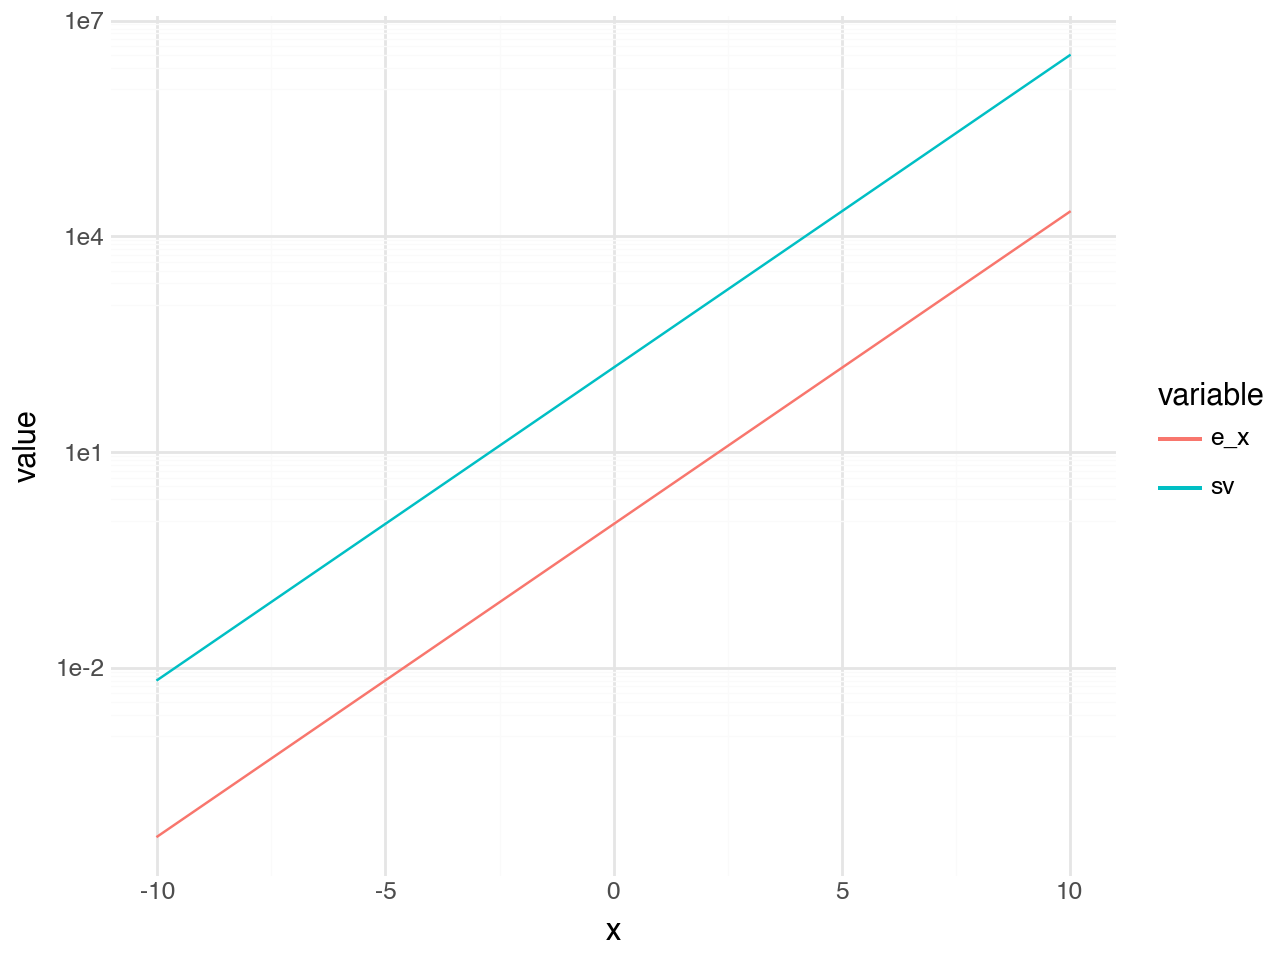

In [6]:
df = pl.DataFrame({
    "x": np.asarray(x),
    "sv": np.asarray(sv),
    "e_x": np.asarray(e_x),
})
df_long = df.unpivot(index=["x"], on=["sv", "e_x"],
                    variable_name="variable", value_name="value")

# plotnine consumes the polars DataFrame directly; `>>` pipes data into the
# plot without converting to pandas.
(
    df_long
    >> (ggplot(aes(x="x", y="value", color="variable"))
        + geom_line()
        + scale_y_log10()
        + labs(x="x", y="value", color="variable")
        + theme_minimal())
)


In [7]:
N_max = int(jnp.ceil((jnp.log(K) / (2*x_max) + 1/4) * (N_x - 1)))
print(N_max, x.shape)
print(jnp.argmin(jnp.abs(x)))

14 (32,)
15


In [8]:
# Final payoff as the initial condition
#V_p = jnp.maximum(K - jnp.exp(x), 0.0)
payoff = jnp.maximum(K - jnp.exp(jnp.log(1/s_max) + delta_x * jnp.arange(N_x/2)), 0.0)

# The coefficient of the initial state
coeff = jnp.zeros_like(x)
coeff = coeff.at[:N_x//2].set(payoff)
coeff = coeff.at[N_x//2:].set(payoff[::-1])

# Normalize the coefficient
coeff = coeff / jnp.linalg.norm(coeff)
coeff = coeff.at[coeff < 1.0e-6].set(1.0e-6)
print(jnp.dot(coeff, coeff))
print(jnp.dot(coeff[:N_x//2], coeff[:N_x//2]))
print("half normal:", jnp.linalg.norm(coeff[:N_x//2]) * jnp.sqrt(2),  "\n"
        "entry normal:", jnp.linalg.norm(coeff))
print(sv[N_max])

1.0
0.49999997
half normal: 0.99999994 
entry normal: 1.0
56.873833


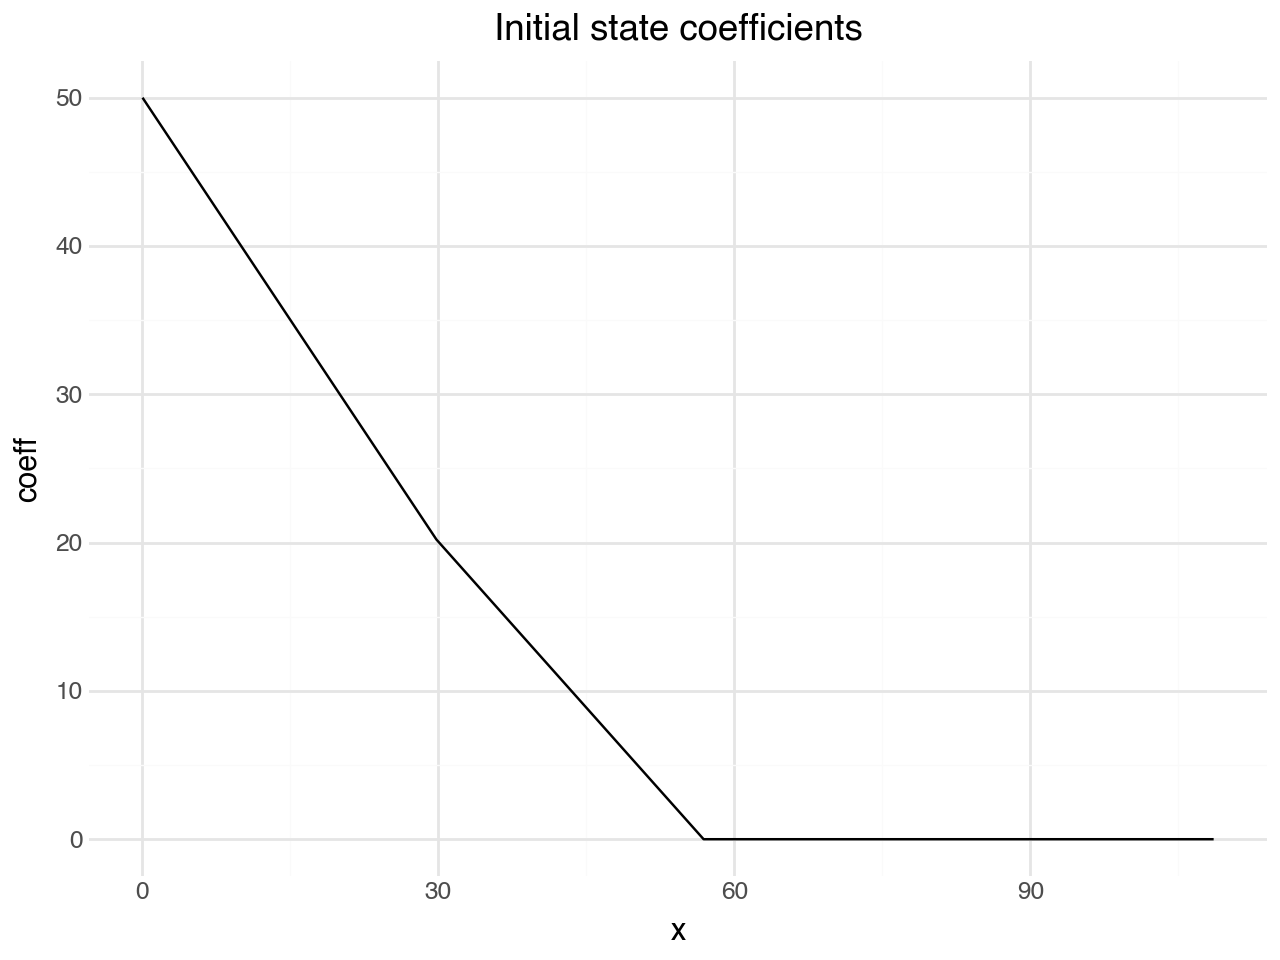

In [9]:
df_coeff = pl.DataFrame({
    "x": np.asarray(sv[:N_x//2]),
    "coeff": np.asarray(payoff[:N_x//2]),
})

(
    df_coeff
    >> (ggplot(aes(x="x", y="coeff"))
        + geom_line()
        + labs(x="x", y="coeff", title="Initial state coefficients")
        + theme_minimal())
)


In [10]:
# Symmetric state loading via QROMStatePreparation: encode only the normalized
# first half of the palindromic coeff with QROM, then mirror it with qubit-0
# H + CNOTs. This halves the data QROM must encode vs the full 512-vector.
phi = coeff[: N_x // 2] / jnp.linalg.norm(coeff[: N_x // 2])

# Configure the wire layout with qp.registers:
#   sym_wire    : 1 wire,  symmetrization (mirror) qubit
#   state_wires : qubits_num-1 wires, load the half-state via QROM
#   prec_wires  : 13 wires, QROM precision register
#   work_wires  : 1 wire,  QROM work register
wires = qp.registers({
    "sym_wire": 1,
    "state_wires": qubits_num - 1,
    "prec_wires": 13,
    "work_wires": 1,
})

dev = qp.device('lightning.qubit',
                wires=wires["sym_wire"] + wires["state_wires"] + wires["prec_wires"] + wires["work_wires"])
shots = 10000

#@qp.decompose(gate_set={"RX", "RY", "RZ", "CZ", "CNOT"}, max_expansion=2)
@qp.simplify
@qp.qnode(dev)
def circuit():
    qp.QROMStatePreparation(phi, wires["state_wires"], wires["prec_wires"], wires["work_wires"])
    qp.Hadamard(wires=wires["sym_wire"])                 # symmetry qubit
    for j in wires["state_wires"]:
        qp.CNOT(wires=[wires["sym_wire"][0], j])         # mirrored half -> full palindromic state
    return qp.probs(wires["sym_wire"] + wires["state_wires"])

prob = circuit()
prob.shape


(32,)

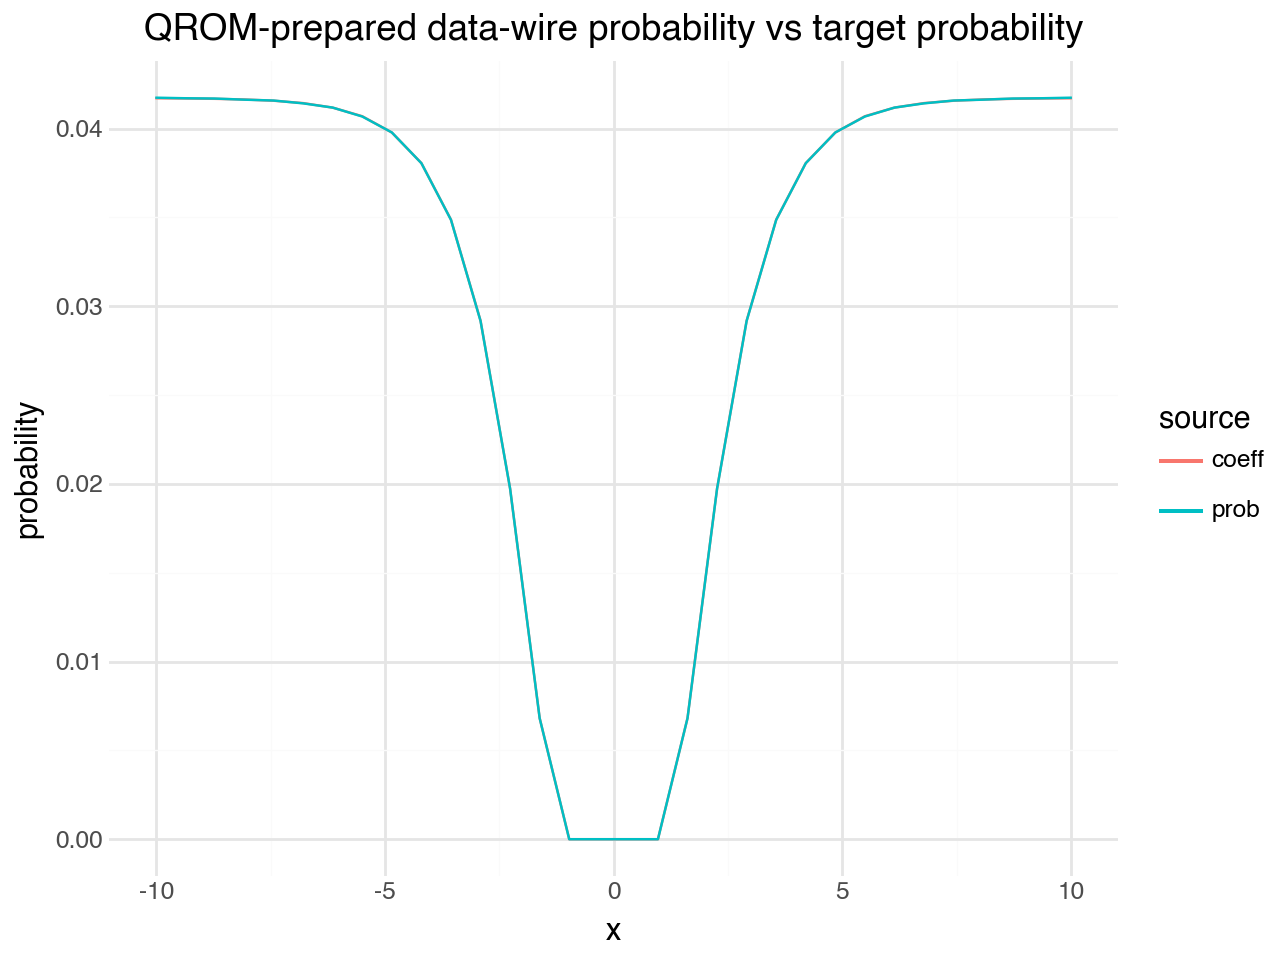

In [11]:
# state and df_coeff show in a figure
df_figure = pl.DataFrame({
    "x": np.asarray(x),
    "coeff": np.asarray(coeff)**2,  # target probability
    "prob": np.asarray(prob),
})
df_figure_long = df_figure.unpivot(index=["x"], on=["coeff", "prob"],
                                 variable_name="source", value_name="probability")

(
    df_figure_long
    >> (ggplot(aes(x="x", y="probability", color="source"))
        + geom_line()
        + labs(x="x", y="probability",
               title="QROM-prepared data-wire probability vs target probability")
        + theme_minimal())
)


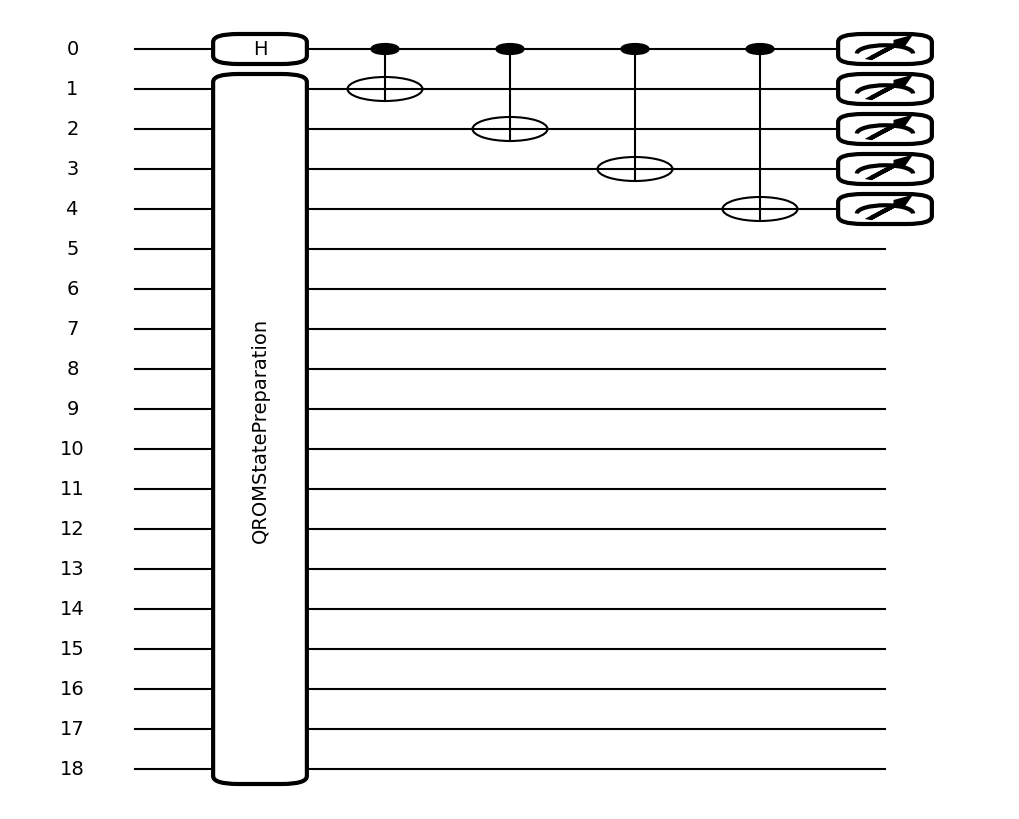

In [12]:
fig, ax = qp.draw_mpl(circuit)()
fig.set_size_inches(10, 8)
plt.show()


In [13]:
qp.specs(circuit)()

Device: lightning.qubit
Device wires: 19
Shots: Shots(total=None)
Level: gradient

Wire allocations: 19
Total gates: 6
Gate counts:
- QROMStatePreparation: 1
- Hadamard: 1
- CNOT: 4
Measurements:
- probs(5 wires): 1
Depth: 5


In [14]:
highlvl_gateset = {
    "RX","RY","RZ",
    "Toffoli",
    "X","Y","Z",
    "Adjoint(S)","Adjoint(T)",
    "Hadamard","S","CNOT","T",
}

lowlvl_gateset = {"Hadamard", "S", "CNOT", "T"}

high_level_es = qre.estimate(circuit, gate_set=highlvl_gateset)()
low_level_es = qre.estimate(circuit, gate_set=lowlvl_gateset)()

print(f"High-level gateset: \n{high_level_es}")
print(f"Low-level gateset: \n{low_level_es}")

High-level gateset: 
--- Resources: ---
 Total wires: 44
   algorithmic wires: 19
   allocated wires: 25
     zero state: 25
     any state: 0
 Total gates : 1.163E+3
   'Adjoint(S)': 13,
   'Toffoli': 112,
   'CNOT': 550,
   'X': 52,
   'S': 13,
   'Hadamard': 423
Low-level gateset: 
--- Resources: ---
 Total wires: 44
   algorithmic wires: 19
   allocated wires: 25
     zero state: 25
     any state: 0
 Total gates : 3.025E+3
   'T': 448,
   'CNOT': 886,
   'S': 1.164E+3,
   'Hadamard': 527


In [15]:
# Decompose StatePrep into elementary gates (official path: StatePrep -> Mottonen -> RY/CNOT)
with qp.tape.QuantumTape() as tape:
    qp.StatePrep(coeff, wires=range(qubits_num))

expanded = tape.expand(depth=10)
ops = expanded.operations
print(f"Total gates: {len(ops)}")
print("Gate types:", dict(Counter(op.name for op in ops)))
print()
print(tape_text(expanded, wire_order=range(qubits_num)))

Total gates: 53
Gate types: {'RY': 23, 'CNOT': 30}

0: ──RY─╭●─────╭●────────╭●────────╭●──────────────────────╭●──────────────────────────╭●─────── ···
1: ──RY─╰X──RY─╰X─╭●─────│──╭●─────│─────────╭●────────────│─────────────╭●────────────│──────── ···
2: ──RY───────────╰X──RY─╰X─╰X──RY─╰X─╭●─────│──────╭●─────│──────╭●─────│──────╭●─────│──────── ···
3: ──RY───────────────────────────────╰X──RY─╰X──RY─╰X──RY─╰X──RY─╰X──RY─╰X──RY─╰X──RY─╰X─╭●──── ···
4: ──RY───────────────────────────────────────────────────────────────────────────────────╰X──RY ···

0: ··· ───────────────────────────────╭●──────────────────────────────────────╭●─┤  
1: ··· ───────────╭●──────────────────│───────────────────╭●──────────────────│──┤  
2: ··· ─╭●────────│─────────╭●────────│─────────╭●────────│─────────╭●────────│──┤  
3: ··· ─│──╭●─────│──╭●─────│──╭●─────│──╭●─────│──╭●─────│──╭●─────│──╭●─────│──┤  
4: ··· ─╰X─╰X──RY─╰X─╰X──RY─╰X─╰X──RY─╰X─╰X──RY─╰X─╰X──RY─╰X─╰X──RY─╰X─╰X──RY─╰X─┤  


In [16]:
# Resource estimation of the state preparation (decomposed: StatePrep -> Mottonen -> RY/CNOT)
with qp.tape.QuantumTape() as tape:
    qp.StatePrep(coeff, wires=range(qubits_num))

expanded = tape.expand(depth=10)
res = expanded.specs['resources']

n_1q = res.gate_sizes.get(1, 0)
n_2q = res.gate_sizes.get(2, 0)

print("=" * 48)
print("State Preparation Resource Estimation")
print("=" * 48)
print(f"Qubits              : {qubits_num}")
print(f"Total gates         : {res.num_gates}")
print(f"  1-qubit gates     : {n_1q}  (RY)")
print(f"  2-qubit gates     : {n_2q}  (CNOT)")
print(f"Circuit depth       : {res.depth}")
print(f"Gate breakdown      : {dict(res.gate_types)}")
print("=" * 48)

State Preparation Resource Estimation
Qubits              : 5
Total gates         : 53
  1-qubit gates     : 23  (RY)
  2-qubit gates     : 30  (CNOT)
Circuit depth       : 49
Gate breakdown      : {'RY': 23, 'CNOT': 30}


In [17]:
# Exploit palindromic symmetry: coeff[i] == coeff[N_x-1-i].
# Prepare the first half on (qubits_num-1) qubits, then symmetrize with 1 H + (qubits_num-1) CNOTs.
# This roughly halves the CNOTs vs full 10-qubit Mottonen StatePrep.
phi = coeff[: N_x // 2]
phi = phi / jnp.linalg.norm(phi)  # normalized half-state

sym_dev = qp.device("default.qubit", wires=qubits_num)  # 9-wire device -> state() is 2^9, matching coeff

@qp.qnode(sym_dev)
def sym_state_prep():
    qp.StatePrep(phi, wires=list(range(1, qubits_num)))  # 9-qubit Mottonen
    qp.Hadamard(wires=0)                                 # symmetry qubit
    for j in range(1, qubits_num):
        qp.CNOT(wires=[0, j])                            # controlled bit-flip -> mirror amplitudes
    return qp.state()

sym_state = sym_state_prep()
print("symmetric prep matches coeff:", bool(jnp.allclose(sym_state, coeff, atol=1e-5)))

# Resource comparison: full Mottonen vs symmetric construction
with qp.tape.QuantumTape() as t_orig:
    qp.StatePrep(coeff, wires=range(qubits_num))
with qp.tape.QuantumTape() as t_sym:
    qp.StatePrep(phi, wires=list(range(1, qubits_num)))
    qp.Hadamard(wires=0)
    for j in range(1, qubits_num):
        qp.CNOT(wires=[0, j])

ro, so = t_orig.expand(depth=10), t_sym.expand(depth=10)
print(f"Original : {ro.specs['resources'].num_gates} gates, depth {ro.specs['resources'].depth}, {dict(ro.specs['resources'].gate_types)}")
print(f"Symmetric: {so.specs['resources'].num_gates} gates, depth {so.specs['resources'].depth}, {dict(so.specs['resources'].gate_types)}")

symmetric prep matches coeff: True
Original : 53 gates, depth 49, {'RY': 23, 'CNOT': 30}
Symmetric: 36 gates, depth 30, {'RY': 15, 'CNOT': 18, 'RZ': 2, 'RX': 1}


In [18]:
# --- Piecewise-constant (zero-order polynomial) state loading ---
# coeff is a smooth payoff. Approximate it by P = 2^k constant pieces, each
# represented by its L2-optimal segment mean. Load the P weights with Mottonen
# on the top k qubits; the lower (qubits_num-k) qubits are uniform within a
# piece -> just Hadamards. Cost O(P) vs O(2^N) for full Mottonen.
coeff_np = np.array(coeff)

def pw_resources_and_fid(P):
    k = int(np.log2(P)); size = N_x // P
    c_raw = np.array([coeff_np[p*size:(p+1)*size].mean() for p in range(P)])
    fid = float(size * np.sum(c_raw**2))      # = ||piecewise-approx||^2 (L2 projection)
    c = c_raw / np.linalg.norm(c_raw)
    with qp.tape.QuantumTape() as t:
        qp.StatePrep(c, wires=list(range(k)))
        for w in range(k, qubits_num):
            qp.Hadamard(wires=w)
    r = t.expand(depth=10).specs['resources']
    return fid, r.num_gates, r.gate_types.get('CNOT', 0), r.depth

print(f"{'P':>5} {'fidelity':>10} {'gates':>7} {'CNOT':>6} {'depth':>7}")
print('-' * 45)
for P in [4, 8, 16]:
    f, g, c, d = pw_resources_and_fid(P)
    print(f"{P:>5} {f:>10.5f} {g:>7} {c:>6} {d:>7}")
# full Mottonen reference on qubits_num wires
with qp.tape.QuantumTape() as t_full:
    qp.StatePrep(coeff_np, wires=range(qubits_num))
r_full = t_full.expand(depth=10).specs['resources']
c_full = r_full.gate_types.get('CNOT', 0)
print(f"{'full':>5} {1.0:>10.5f} {r_full.num_gates:>7} {c_full:>6} {r_full.depth:>7}   <- full Mottonen")


    P   fidelity   gates   CNOT   depth
---------------------------------------------
    4    0.90083      14      2       4
    8    0.97081      19      6      11
   16    0.99637      32     14      26
 full    1.00000      61     30      57   <- full Mottonen


In [19]:
# Chosen configuration: P=16 -> piecewise-constant approximation state load
# Each element of piece p gets amplitude piece_mean[p]/sqrt(size); this is exactly
# the tensor product (StatePrep on top k qubits) x (Hadamards on lower qubits).
# P=16 (k=4, size=2) gives ~99.6% fidelity with only 14 CNOTs; P needs to be
# >= 16 to keep the end-to-end QFT/QSVT error budget acceptable.
P = 16
k = int(np.log2(P)); size = N_x // P
piece_mean = np.array([coeff_np[p*size:(p+1)*size].mean() for p in range(P)])
piece_mean = piece_mean / np.linalg.norm(piece_mean)

pw_dev = qp.device('default.qubit', wires=qubits_num)

@qp.qnode(pw_dev)
def pw_state_prep():
    qp.StatePrep(piece_mean, wires=list(range(k)))   # top k MSB qubits: piece weights
    for w in range(k, qubits_num):
        qp.Hadamard(wires=w)                          # lower qubits: uniform within piece
    return qp.state()

pw_state = pw_state_prep()
fid = float(jnp.abs(jnp.sum(jnp.conj(pw_state) * coeff))**2)  # overlap with true coeff
print(f"P={P}: overlap with full coeff = {fid:.5f}")

# reconstitute the full approximated amplitude vector (for plotting/verification)
pw_amp = np.repeat(np.asarray(piece_mean) / np.sqrt(size), size)
print("||reconstituted approx||^2 =", float(np.sum(pw_amp**2)))


P=16: overlap with full coeff = 0.99637
||reconstituted approx||^2 = 1.00000002876757


# Hamiltonian 

In [4]:
from jax.scipy.linalg import expm
# Option parameters
rate = 0.04
sigma = 0.2
maturity = 1.0
eigenvalues = jnp.sin(2 * jnp.pi * jnp.arange(N_x) / N_x) / delta_x
eigen_diag = jnp.diag(eigenvalues)
Hamiltonian =  (0.5 * sigma **2 *eigen_diag**2 + rate * jnp.eye(N_x))
exp_Hamiltonian = expm(- Hamiltonian * maturity)
print(exp_Hamiltonian)
Hamiltonian.shape


[[0.96078944 0.         0.         ... 0.         0.         0.        ]
 [0.         0.95904136 0.         ... 0.         0.         0.        ]
 [0.         0.         0.95408076 ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.94670457 0.         0.        ]
 [0.         0.         0.         ... 0.         0.95408076 0.        ]
 [0.         0.         0.         ... 0.         0.         0.95904136]]


(32, 32)

/Users/knight/miniforge3/envs/quantumlab/lib/python3.12/site-packages/numpy/polynomial/polynomial.py:1467: RankWarning: The fit may be poorly conditioned


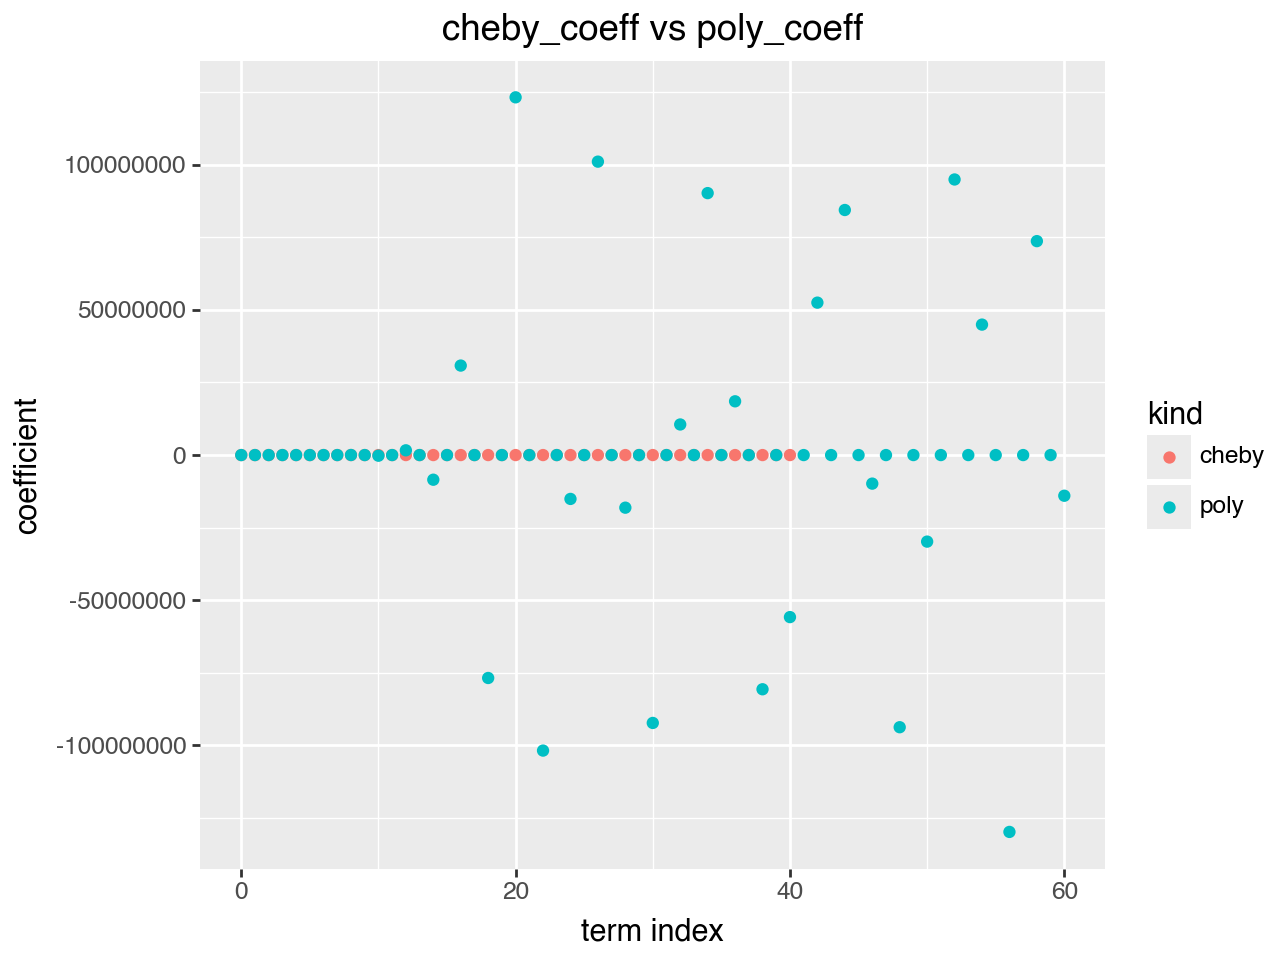

In [5]:
# polynomial fitting for QSVT of exp(-maturity*Hamiltonian)
# BlockEncode normalizes the matrix, so the poly sees singular values in (-1,1).
# Fit the EVEN target exp(-maturity*m*|x|) on the normalized domain, x in [-1,1].
m = float(np.max(np.abs(np.diag(Hamiltonian))))  # spectral-norm scale BlockEncode applies
xs = np.linspace(-1.0, 1.0, 1001)
cheby_coeff = np.polynomial.chebyshev.chebfit(xs, np.exp(-maturity * m * np.abs(xs)), 40)
cheby_coeff[1::2] = 0.0  # QSVT requires even parity
#poly_coeff = np.polynomial.chebyshev.cheb2poly(cheby_coeff)
poly_coeff = np.polynomial.polynomial.polyfit(xs, np.exp(-maturity * m * np.abs(xs)), 60)
poly_coeff[1::2] = 0.0  # QSVT requires even parity

# coefficient values vs term index (Chebyshev vs power basis)
coef_df = pl.DataFrame({
    "kind": ["cheby"] * cheby_coeff.size + ["poly"] * poly_coeff.size,
    "index": list(range(cheby_coeff.size)) + list(range(poly_coeff.size)),
    "value": np.concatenate([cheby_coeff, poly_coeff]),
})
(coef_df
    >> (ggplot(aes(x="index", y="value", color="kind"))
    + geom_point(size=1.5)
    + labs(title="cheby_coeff vs poly_coeff", x="term index", y="coefficient"))
)


[-3.92699082  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633
  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633
  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633
  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633
  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633  1.57079633
  0.29580338  1.71332754  1.53414859  1.5887286   1.55982504  1.57828478
  1.56530999  1.57497836  1.56749108  1.5734495   1.56861927  1.5725896
  1.56930212  1.57203874  1.56976716  1.5716449   1.57012373  1.57132207
  1.57045126  1.57099325  1.57080242  1.57072712  1.57087998  1.57091486
  1.57086     1.57081661  1.5708006   1.57079694  1.57079638  1.57079633
  0.78539816]
[[0.96073544 0.         0.         ... 0.         0.         0.        ]
 [0.         0.95907027 0.         ... 0.         0.         0.        ]
 [0.         0.         0.9540802  ... 0.         0.         0.        ]
 ...
 [0.         0.         0.       

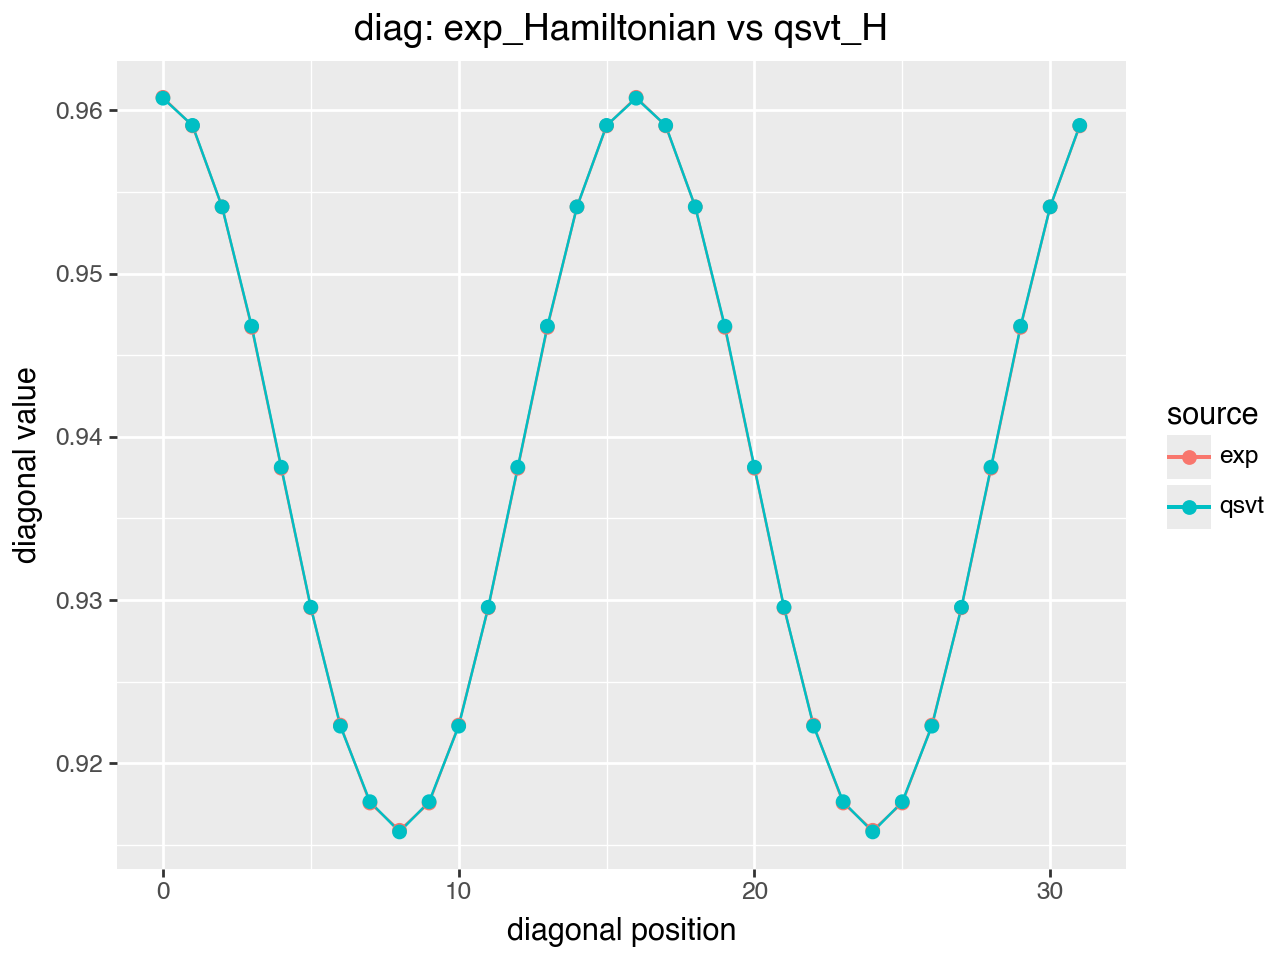

In [6]:
# angle of polynomial
angle_pl = qp.poly_to_angles(poly_coeff, "QSVT")
print(angle_pl)
qsvt_H = qp.matrix(qp.qsvt(Hamiltonian/m, poly_coeff, encoding_wires=range(2*qubits_num+1),
                    block_encoding="embedding"))
print(qsvt_H.real[:N_x, :N_x])
# diagonal SSR as before (normalized by max diag, squared, NOT divided by N)
diag_ssr = np.linalg.norm(abs(exp_Hamiltonian.diagonal()-qsvt_H.real[:N_x, :N_x].diagonal())
                         / exp_Hamiltonian.diagonal().max())**2
# relative Frobenius error of the full 32x32 block (scale- and size-invariant)
fro_err = np.linalg.norm(exp_Hamiltonian[:N_x,:N_x] - qsvt_H.real[:N_x,:N_x]) \
        / np.linalg.norm(exp_Hamiltonian[:N_x,:N_x])
print("diag SSR (max-diag normalized):", diag_ssr)
print("relative Frobenius error:  ", fro_err)

# compare exp vs QSVT diagonal values point by point
diag_df = pl.DataFrame({
    "index": list(range(N_x)) + list(range(N_x)),
    "source": ["exp"] * N_x + ["qsvt"] * N_x,
    "value": np.concatenate([exp_Hamiltonian.diagonal(), qsvt_H.real[:N_x, :N_x].diagonal()]),
})
(diag_df
    >> (ggplot(aes(x="index", y="value", color="source"))
    + geom_line()
    + geom_point(size=2)
    + labs(title="diag: exp_Hamiltonian vs qsvt_H", x="diagonal position", y="diagonal value"))
)


In [21]:
#print(jnp.equal(coeff **2, prob))

# Paper-aligned Hamiltonian simulation

In [7]:
# III. Paper-aligned Hamiltonian simulation and ancilla post-selection
config = BlackScholesConfig(n_qubits=6, s_max=s_max, strike=K, rate=r, volatility=sigma, maturity=T)
simulator = BlackScholesSimulator(config)

#spot price for the option
spot = simulator.stock_grid[:simulator.size//2][0]

# Simulation outcome
result = simulator.run(time=T, spot=spot)
print(f'grid points: {simulator.size}')
print(f'ancilla |0> success probability: {result.success_probability:.6f}')
print(f'discrete put price near S={spot}: {result.price:.6f}')

grid points: 64
ancilla |0> success probability: 0.921128
discrete put price near S=0.006666666666666668: 48.032598


In [8]:
# black-scholes analysis solution

d1 = (jnp.log(spot / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * jnp.sqrt(T))
d2 = d1 - sigma * jnp.sqrt(T) 
put_price = K * jnp.exp(-r * T) * jax.scipy.stats.norm.cdf(-d2) - spot * jax.scipy.stats.norm.cdf(-d1)
print(f"Black-Scholes put price near S={spot}: {put_price:.6f}")

Black-Scholes put price near S=0.006666666666666668: 48.032803


In [9]:
# Positive-momentum convention: payoff → inverse QFT → H-control / QSVT-vs-conjugate / H-control → drift → QFT; post-select final control measurement 0 and FABLE ancillas 0 to select (U + U†)/2.
qnode = simulator.pennylane_qnode(time=T, shots=None, qsvt_degree=50)
probabilities = qnode()
quantum_result = simulator.price_from_pennylane_probabilities(probabilities, spot=spot, time=T)
print(f"QSVT real-part/FABLE post-selection probability: {quantum_result.success_probability:.6f}")
print(f"physical grid uses indices 0..{simulator.size // 2 - 1} of {simulator.size} total points")
print(f"price from physical half-grid point at S={spot}: {quantum_result.price:.6f}")
print(qp.draw(qnode)())


/Users/knight/miniforge3/envs/quantumlab/lib/python3.12/site-packages/numpy/polynomial/polynomial.py:1467: RankWarning: The fit may be poorly conditioned


QSVT real-part/FABLE post-selection probability: 0.568615
physical grid uses indices 0..31 of 64 total points
price from physical half-grid point at S=0.006666666666666668: 37.700806
 0: ──H────────────────────────╭○────╭●──────H──────────┤ ╭Probs
 1: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 2: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 3: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 4: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 5: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 6: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 7: ───────────────────────────├QSVT─├QSVT†─────────────┤ ├Probs
 8: ──H───╭●─╭●─╭●─╭●─╭●─╭QFT†─├QSVT─├QSVT†─╭U(M0)─╭QFT─┤ ├Probs
 9: ─╭|Ψ⟩─╰X─│──│──│──│──├QFT†─├QSVT─├QSVT†─├U(M0)─├QFT─┤ ├Probs
10: ─├|Ψ⟩────╰X─│──│──│──├QFT†─├QSVT─├QSVT†─├U(M0)─├QFT─┤ ├Probs
11: ─├|Ψ⟩───────╰X─│──│──├QFT†─├QSVT─├QSVT†─├U(M0)─├QFT─┤ ├Probs
12: ─├|Ψ⟩──────────╰X─│──├QFT†─├QSVT─

In [7]:
qre.estimate(qnode)()

--- Resources: ---
 Total wires: 20
   algorithmic wires: 14
   allocated wires: 6
     zero state: 6
     any state: 0
 Total gates : 2.526E+7
   'Toffoli': 1.884E+5,
   'T': 2.451E+7,
   'CNOT': 5.605E+5,
   'X': 2.258E+3,
   'Hadamard': 4.491E+3


In [26]:
#print(qp.draw(qp.decompose(qnode, max_expansion=10))())


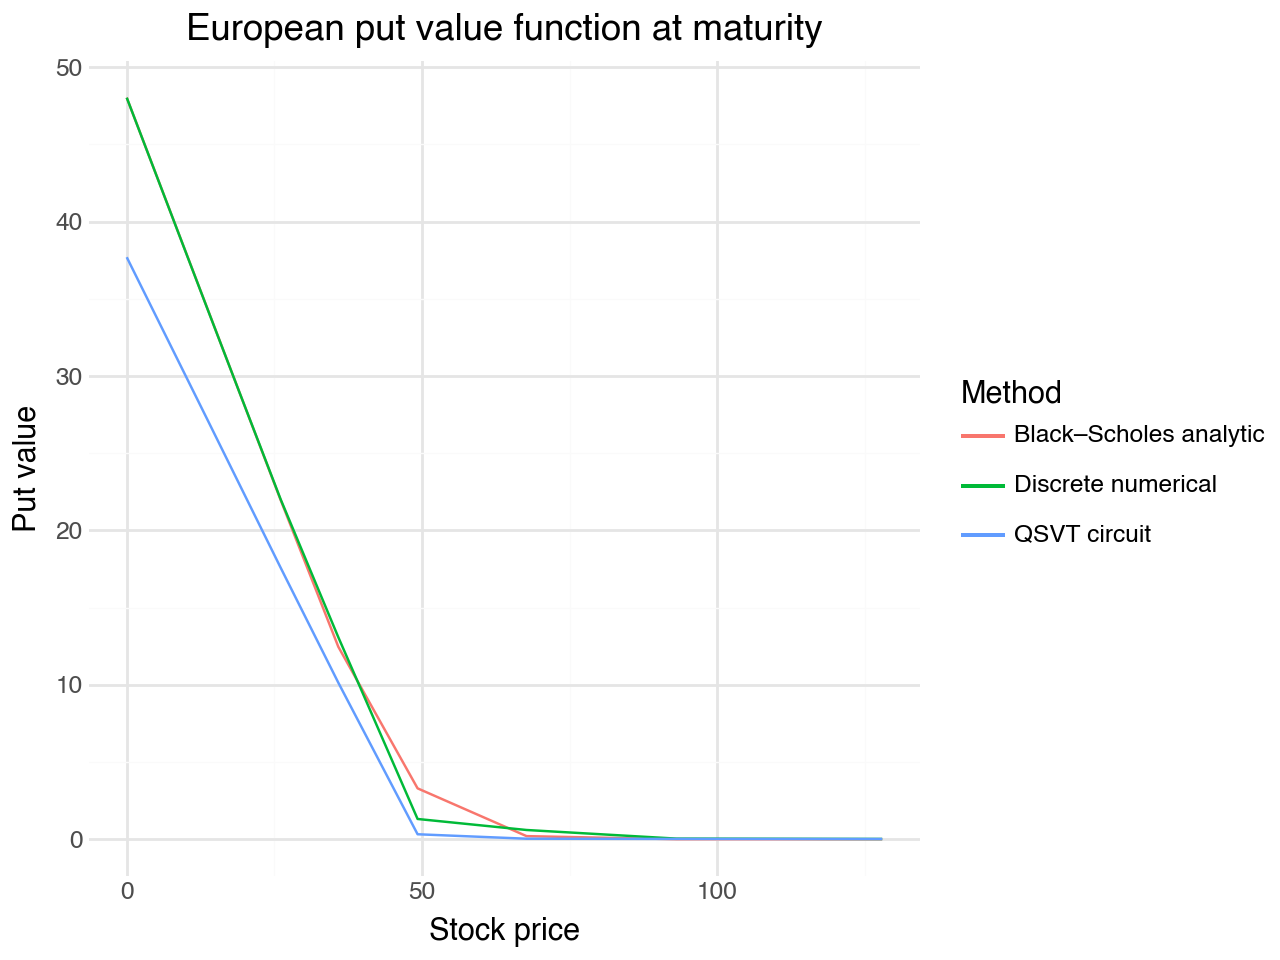

In [10]:
# Compare the final put-value function on the simulator's physical half-grid.
# Reuse the statevector probabilities from the QSVT QNode above (shots=None).
physical_size = simulator.size // 2
stock_values = simulator.stock_grid[:physical_size]
config = simulator.config
time_value = T

# Black–Scholes analytic value, evaluated at exactly the same stock points.
vol = config.volatility
rate_value = config.rate
strike_value = config.strike
d1_grid = (np.log(stock_values / strike_value) + (rate_value + 0.5 * vol**2) * time_value) / (vol * np.sqrt(time_value))
d2_grid = d1_grid - vol * np.sqrt(time_value)
analytic_values = (
    strike_value * np.exp(-rate_value * time_value) * np.asarray(jax.scipy.stats.norm.cdf(-d2_grid))
    - stock_values * np.asarray(jax.scipy.stats.norm.cdf(-d1_grid))
)

# Exact discrete simulator reference and QSVT circuit result. The price at each
# grid point is sqrt(normalization × joint post-selection probability).
discrete_state = simulator.selected_state(time_value)
discrete_values = np.sqrt(simulator.normalization) * np.abs(discrete_state[:physical_size])
qsvt_joint_probabilities = np.asarray(probabilities, dtype=float)[:simulator.size]
qsvt_values = np.sqrt(simulator.normalization * np.maximum(qsvt_joint_probabilities[:physical_size], 0.0))

value_df = pl.DataFrame({
    "Stock price": np.tile(stock_values, 3),
    "Option value": np.concatenate([analytic_values, discrete_values, qsvt_values]),
    "Method": (
        ["Black–Scholes analytic"] * physical_size
        + ["Discrete numerical"] * physical_size
        + ["QSVT circuit"] * physical_size
    ),
})
(
    value_df
    >> (ggplot(aes(x="Stock price", y="Option value", color="Method"))
        + geom_line()
        + labs(
            title="European put value function at maturity",
            x="Stock price",
            y="Put value",
            color="Method",
        )
        + theme_minimal())
)


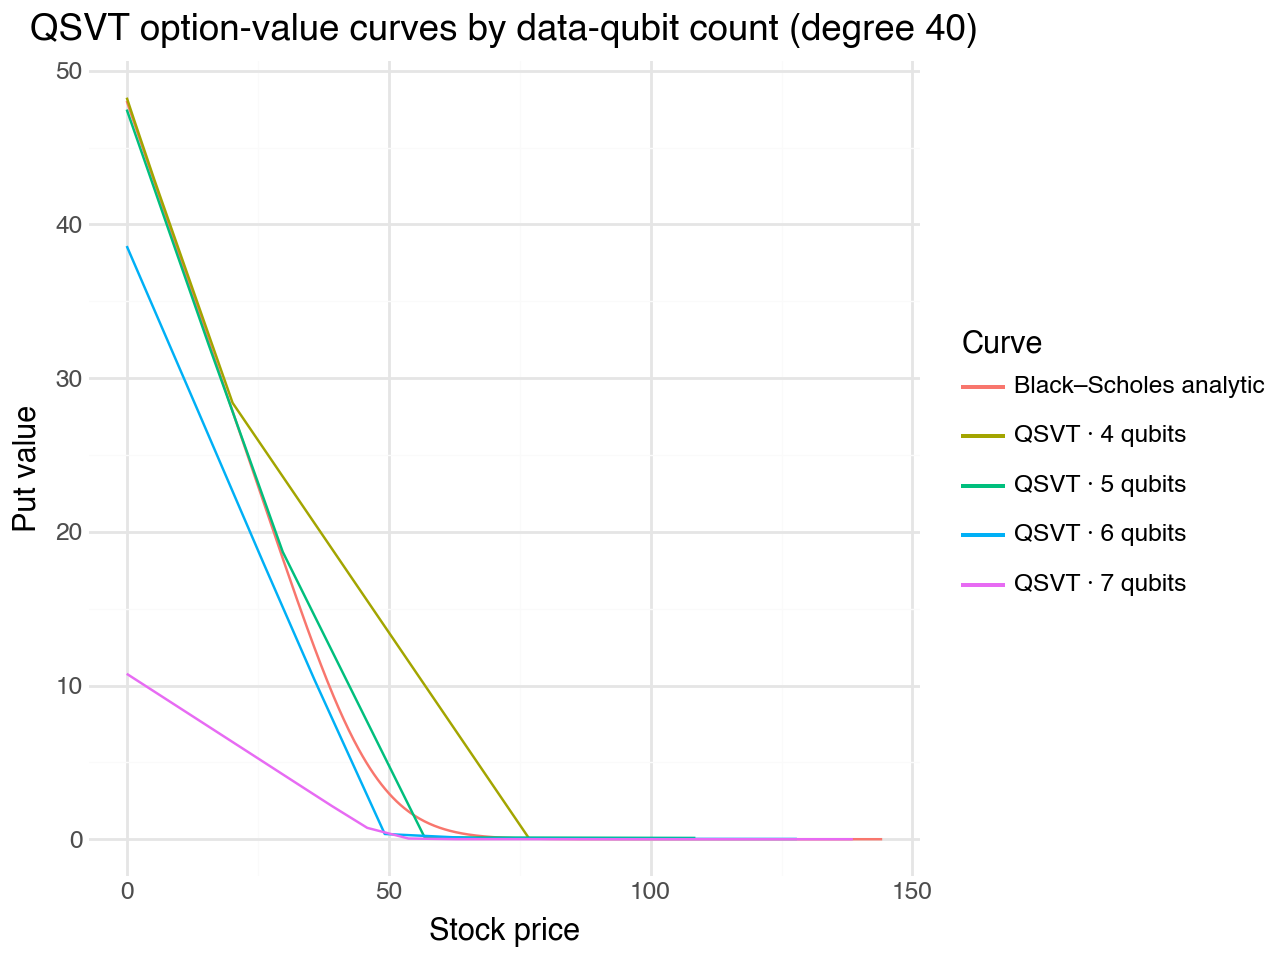

In [30]:
# Compare QSVT price curves for 4–8 data qubits with the continuous Black–Scholes value.
# Each QSVT series is computed from its own PennyLane statevector circuit.
qsvt_degree = 40
time_value = T
curve_rows = []

# Dense analytic reference for a smooth, readable line.
reference_simulator = BlackScholesSimulator(BlackScholesConfig(
    n_qubits=8, s_max=s_max, strike=K, rate=r, volatility=sigma, maturity=T
))
reference_stock = np.linspace(
    reference_simulator.stock_grid[0],
    reference_simulator.stock_grid[reference_simulator.size // 2 - 1],
    600,
)
reference_d1 = (
    np.log(reference_stock / K) + (r + 0.5 * sigma**2) * time_value
) / (sigma * np.sqrt(time_value))
reference_d2 = reference_d1 - sigma * np.sqrt(time_value)
reference_value = (
    K * np.exp(-r * time_value) * np.asarray(jax.scipy.stats.norm.cdf(-reference_d2))
    - reference_stock * np.asarray(jax.scipy.stats.norm.cdf(-reference_d1))
)
curve_rows.append(pl.DataFrame({
    "Stock price": reference_stock,
    "Put value": reference_value,
    "Curve": ["Black–Scholes analytic"] * len(reference_stock),
}))

for data_qubits in range(4, 8):
    bit_simulator = BlackScholesSimulator(BlackScholesConfig(
        n_qubits=data_qubits,
        s_max=s_max,
        strike=K,
        rate=r,
        volatility=sigma,
        maturity=T,
    ))
    bit_probabilities = np.asarray(
        bit_simulator.pennylane_qnode(
            time=time_value, shots=None, qsvt_degree=qsvt_degree
        )(),
        dtype=float,
    )
    physical_size = bit_simulator.size // 2
    bit_stock = bit_simulator.stock_grid[:physical_size]
    # First 2**n entries are the joint control/FABLE-postselection outcome;
    # multiplying by payoff normalization converts amplitudes to option values.
    bit_joint_probabilities = bit_probabilities[:bit_simulator.size]
    bit_values = np.sqrt(
        bit_simulator.normalization
        * np.maximum(bit_joint_probabilities[:physical_size], 0.0)
    )
    curve_rows.append(pl.DataFrame({
        "Stock price": bit_stock,
        "Put value": bit_values,
        "Curve": [f"QSVT · {data_qubits} qubits"] * physical_size,
    }))

bit_curve_df = pl.concat(curve_rows)
(
    bit_curve_df
    >> (ggplot(aes(x="Stock price", y="Put value", color="Curve", group="Curve"))
        + geom_line()
        + labs(
            title=f"QSVT option-value curves by data-qubit count (degree {qsvt_degree})",
            x="Stock price",
            y="Put value",
            color="Curve",
        )
        + theme_minimal())
)


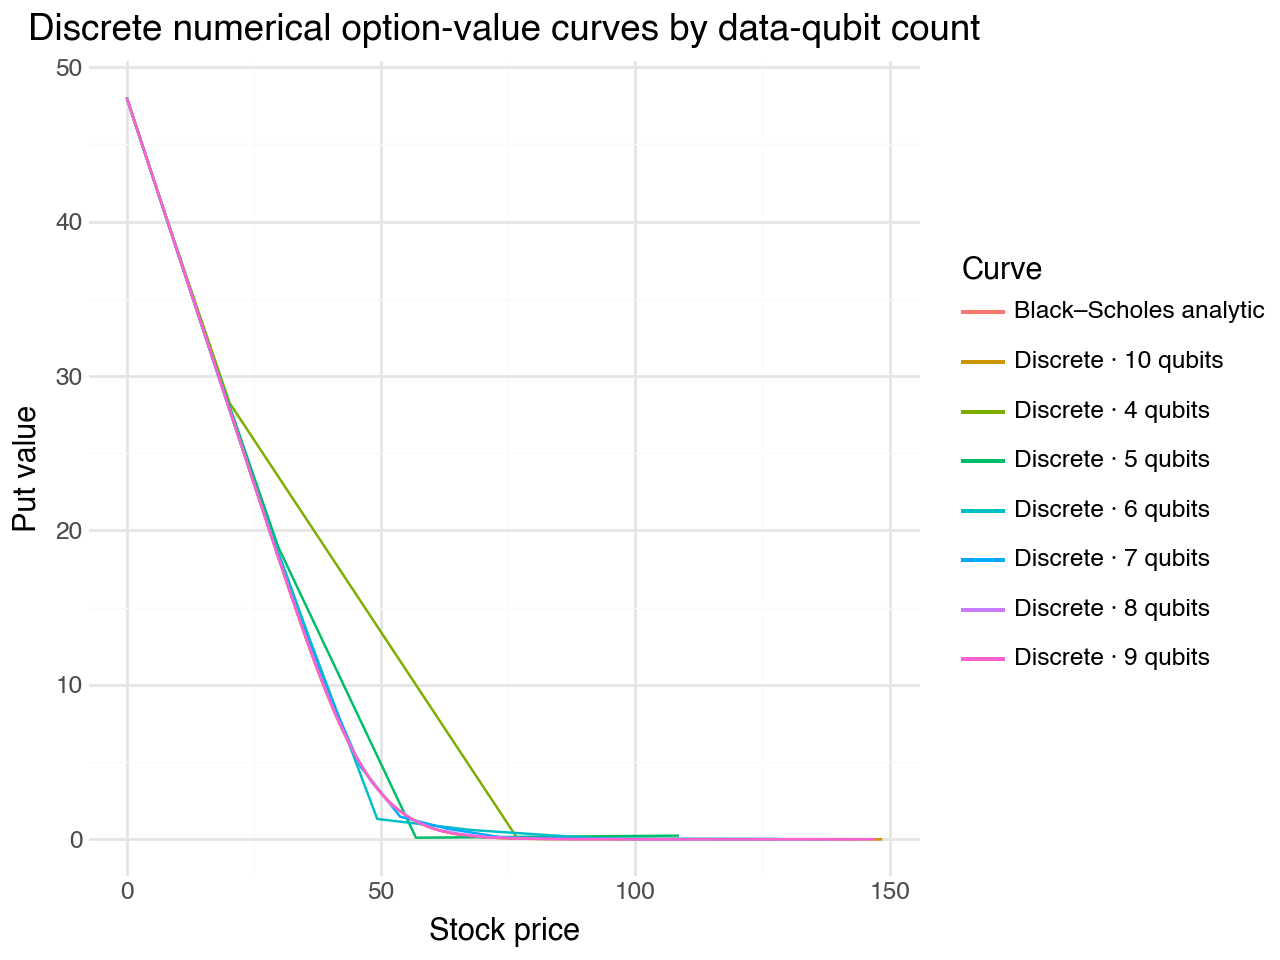

In [29]:
# Compare discrete numerical and analytic put-value functions for 4–10 data qubits.
discrete_curve_rows = []
time_value = T

# Continuous analytic reference spans the physical stock-price range of the grids.
reference_simulator = BlackScholesSimulator(BlackScholesConfig(
    n_qubits=10, s_max=s_max, strike=K, rate=r, volatility=sigma, maturity=T
))
reference_stock = np.linspace(
    reference_simulator.stock_grid[0],
    reference_simulator.stock_grid[reference_simulator.size // 2 - 1],
    800,
)
reference_d1 = (
    np.log(reference_stock / K) + (r + 0.5 * sigma**2) * time_value
) / (sigma * np.sqrt(time_value))
reference_d2 = reference_d1 - sigma * np.sqrt(time_value)
reference_value = (
    K * np.exp(-r * time_value) * np.asarray(jax.scipy.stats.norm.cdf(-reference_d2))
    - reference_stock * np.asarray(jax.scipy.stats.norm.cdf(-reference_d1))
)
discrete_curve_rows.append(pl.DataFrame({
    "Stock price": reference_stock,
    "Put value": reference_value,
    "Curve": ["Black–Scholes analytic"] * len(reference_stock),
}))

for data_qubits in range(4, 11):
    grid_simulator = BlackScholesSimulator(BlackScholesConfig(
        n_qubits=data_qubits,
        s_max=s_max,
        strike=K,
        rate=r,
        volatility=sigma,
        maturity=T,
    ))
    physical_size = grid_simulator.size // 2
    stock_values = grid_simulator.stock_grid[:physical_size]
    # selected_state is the FFT-based discrete Hamiltonian evolution, without QSVT.
    evolved_state = grid_simulator.selected_state(time_value)
    discrete_values = np.sqrt(grid_simulator.normalization) * np.abs(
        evolved_state[:physical_size]
    )
    discrete_curve_rows.append(pl.DataFrame({
        "Stock price": stock_values,
        "Put value": discrete_values,
        "Curve": [f"Discrete · {data_qubits} qubits"] * physical_size,
    }))

discrete_curve_df = pl.concat(discrete_curve_rows)
(
    discrete_curve_df
    >> (ggplot(aes(x="Stock price", y="Put value", color="Curve", group="Curve"))
        + geom_line()
        + labs(
            title="Discrete numerical option-value curves by data-qubit count",
            x="Stock price",
            y="Put value",
            color="Curve",
        )
        + theme_minimal())
)
